# 2. Training and evaluation

How the model was trained and how well it does on years it never saw.

By default this notebook evaluates the saved model in `artifacts/`. Set `RETRAIN =
True` to retrain it first with `train.train()` (about 80 seconds), which overwrites
`artifacts/`. Training is deterministic, so a retrain gives the same model.

| Step | Years | What happens |
|---|---|---|
| Fit | 2010-2017 | First fit, to choose the number of trees |
| Early stopping | 2018 | Stops when PR-AUC (`eval_metric="aucpr"`) stops improving |
| Refit | 2010-2018 | Final model with that many trees |
| Calibration | 2019-2020 | Isotonic regression maps raw scores to probabilities |
| Test | 2021-2024 | Only used here, to measure the model |

In [1]:
import viz

viz.setup()

import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ml.wildfire import features as F
from ml.wildfire import sources
from ml.wildfire.config import (
    ARTIFACTS_DIR, CALIBRATION_YEARS, DATASET_PATH, FIRST_YEAR, LAST_YEAR,
    REFERENCE_PATH, REFIT_YEARS, TEST_YEARS, USER_AGENT,
)

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)

from sklearn.metrics import average_precision_score, precision_recall_curve

from ml.wildfire import train
from ml.wildfire.model import WildfireModel

In [2]:
RETRAIN = False

if RETRAIN:
    import logging

    logging.basicConfig(level=logging.INFO, format="%(asctime)s %(message)s", force=True)
    train.train()

meta = json.loads((ARTIFACTS_DIR / "metadata.json").read_text(encoding="utf-8"))
metrics = meta["metrics"]
print("Trained at:", meta["trained_at"])
print("Target:", meta["target"])

Trained at: 2026-11-21T19:17:50+00:00
Target: A large wildfire (MTBS: ~1,000+ acres West, ~500+ acres East) ignites in the county during the week (Monday-Sunday)


In [3]:
pd.Series(
    {
        "Trees (from early stopping)": meta["n_trees"],
        "scale_pos_weight, refit (no-fire / fire rows)": round(meta["scale_pos_weight"], 1),
        "scale_pos_weight, stage 1 fit": round(meta["scale_pos_weight_stage1"], 1),
        "Training rows / fires": f"{meta['training_rows']:,} / {meta['training_fires']:,}",
        "Calibration rows / fires": f"{meta['calibration_rows']:,} / {meta['calibration_fires']:,}",
        **{f"param: {k}": v for k, v in meta["params"].items()},
    },
    name="value",
).to_frame()

,value
Trees (from early stopping),335
"scale_pos_weight, refit (no-fire / fire rows)",414.4
"scale_pos_weight, stage 1 fit",420.8
Training rows / fires,"1,510,649 / 3,637"
Calibration rows / fires,"338,205 / 714"
param: objective,binary:logistic
param: eval_metric,aucpr
param: tree_method,hist
param: learning_rate,0.03
param: max_depth,6


## Early stopping

PR-AUC on 2018 after each tree of the first fit. Training stops 150 trees after the
best one, and the refit uses the best count.

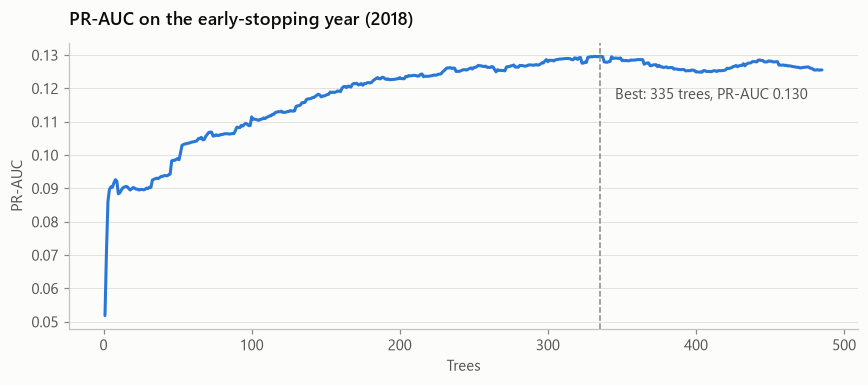

In [4]:
curve = np.array(metrics["early_stopping_aucpr"])
best = meta["n_trees"]
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(np.arange(1, len(curve) + 1), curve, color=viz.BLUE)
ax.axvline(best, color=viz.INK_MUTED, linestyle="--", linewidth=1)
ax.annotate(f"Best: {best} trees, PR-AUC {curve[best - 1]:.3f}", (best, curve[best - 1]),
            xytext=(10, -28), textcoords="offset points", color=viz.INK_SECONDARY)
ax.set_title("PR-AUC on the early-stopping year (2018)")
ax.set_xlabel("Trees")
ax.set_ylabel("PR-AUC")
viz.finish(ax)
viz.show()

## Test predictions

The model scores every 2021-2024 county-week. The **baseline** predicts each county's
2010-2020 fire rate for that month, which is what you'd get from fire history alone.
These numbers are recomputed here and checked against the ones `train.py` saved.

In [5]:
model = WildfireModel.load()
data = pd.read_parquet(DATASET_PATH)
test = data[data["year"].isin(list(TEST_YEARS))]
y = test["fire"].to_numpy()
raw = model.predict_raw(test)
prob = model.calibrate(raw)

history = data[data["year"] <= max(CALIBRATION_YEARS)]
county_month_rate = history.groupby([history["fips"], F.week_month(history["week_start"])])["fire"].mean()
keys = pd.MultiIndex.from_arrays([test["fips"], F.week_month(test["week_start"])])
baseline = county_month_rate.reindex(keys).fillna(0).to_numpy()

assert np.isclose(average_precision_score(y, prob), metrics["calibrated"]["pr_auc"])
assert np.isclose(average_precision_score(y, baseline), metrics["baseline_county_month_rate"]["pr_auc"])
print(f"{len(test):,} test county-weeks, {y.sum():,} fires. Matches the saved metrics.")

669,968 test county-weeks, 1,442 fires. Matches the saved metrics.


In [6]:
labels = {
    "pr_auc": "PR-AUC",
    "roc_auc": "ROC-AUC",
    "recall_top5pct": "Fires caught in top 5% of county-weeks",
    "precision_top1pct": "Fire rate in top 1% of county-weeks",
    "log_loss": "Log loss (lower is better)",
    "brier": "Brier score (lower is better)",
    "mean_predicted": "Mean predicted probability",
    "observed_rate": "Observed fire rate",
}
table = pd.DataFrame(
    {
        "Model (calibrated)": metrics["calibrated"],
        "Model (raw)": metrics["raw"],
        "Baseline": metrics["baseline_county_month_rate"],
    }
).loc[list(labels)].rename(index=labels)
table.style.format("{:.4f}")

,Model (calibrated),Model (raw),Baseline
PR-AUC,0.0809,0.0863,0.0657
ROC-AUC,0.9525,0.9537,0.7921
Fires caught in top 5% of county-weeks,0.7379,0.7323,0.5915
Fire rate in top 1% of county-weeks,0.0770,0.0773,0.0682
Log loss (lower is better),0.0107,0.1808,0.0191
Brier score (lower is better),0.0021,0.0563,0.0021
Mean predicted probability,0.0027,0.1006,0.0024
Observed fire rate,0.0022,0.0022,0.0022


The model ranks risk much better than fire history alone. Log loss and Brier only
mean something for calibrated probabilities: the raw model's average prediction is
about 10%, against a real fire rate of about 0.2%.

## How many fires does each approach catch?

Sort county-weeks from most to least risky and flag the top share. The y value is the
share of all test fires inside the flagged set.

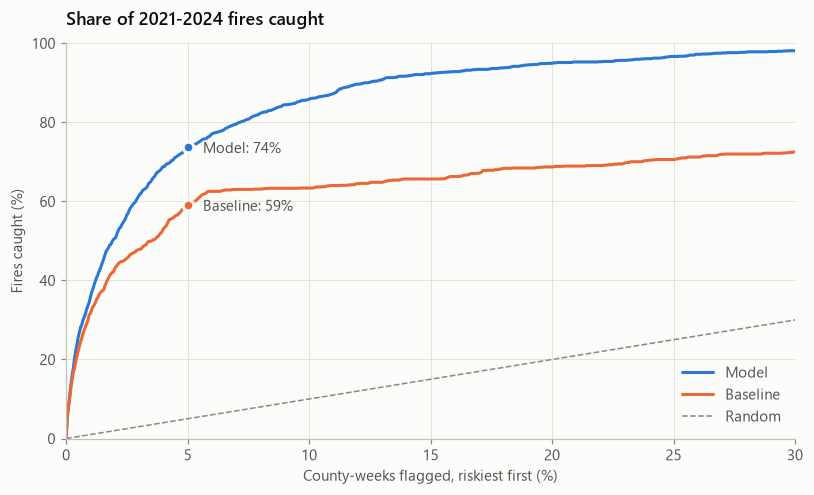

In [7]:
def capture(scores):
    # Same sort as train.metrics, so tied scores fall the same way as the saved numbers.
    order = np.argsort(-scores)
    caught = np.cumsum(y[order]) / y.sum()
    share = np.arange(1, len(y) + 1) / len(y)
    return share, caught


fig, ax = plt.subplots(figsize=(7.5, 4.6))
for name, scores, color in (("Model", prob, viz.BLUE), ("Baseline", baseline, viz.ORANGE)):
    share, caught = capture(scores)
    step = max(1, len(share) // 2000)
    ax.plot(share[::step] * 100, caught[::step] * 100, color=color, label=name)
    at5 = caught[int(0.05 * len(y)) - 1] * 100
    ax.plot(5, at5, "o", color=color, markersize=7, markeredgecolor=viz.SURFACE, markeredgewidth=2)
    ax.annotate(f"{name}: {at5:.0f}%", (5, at5), xytext=(10, -4), textcoords="offset points",
                color=viz.INK_SECONDARY)
ax.plot([0, 100], [0, 100], color=viz.INK_MUTED, linestyle="--", linewidth=1, label="Random")
ax.set_xlim(0, 30)
ax.set_ylim(0, 100)
ax.set_title("Share of 2021-2024 fires caught")
ax.set_xlabel("County-weeks flagged, riskiest first (%)")
ax.set_ylabel("Fires caught (%)")
ax.legend(loc="lower right")
viz.finish(ax, "both")
viz.show()

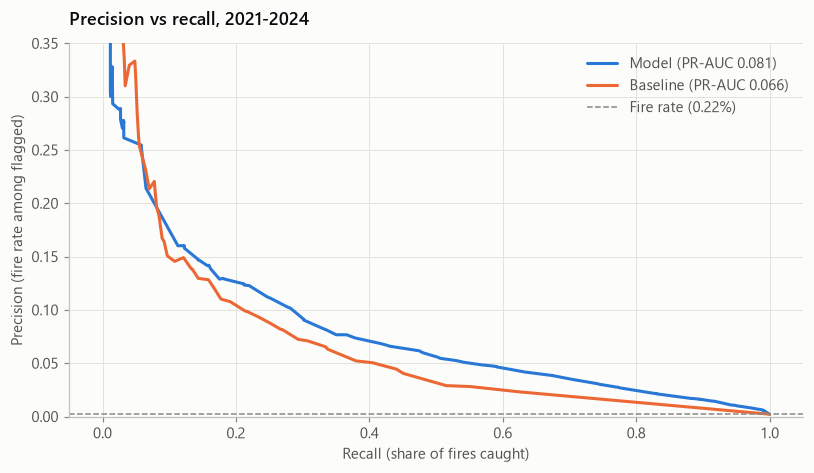

In [8]:
fig, ax = plt.subplots(figsize=(7.5, 4.4))
for name, scores, color in (("Model", prob, viz.BLUE), ("Baseline", baseline, viz.ORANGE)):
    precision, recall, _ = precision_recall_curve(y, scores)
    ap = average_precision_score(y, scores)
    ax.plot(recall, precision, color=color, label=f"{name} (PR-AUC {ap:.3f})")
ax.axhline(y.mean(), color=viz.INK_MUTED, linestyle="--", linewidth=1, label=f"Fire rate ({y.mean():.2%})")
ax.set_ylim(0, 0.35)
ax.set_title("Precision vs recall, 2021-2024")
ax.set_xlabel("Recall (share of fires caught)")
ax.set_ylabel("Precision (fire rate among flagged)")
ax.legend(loc="upper right")
viz.finish(ax, "both")
viz.show()

## Calibration

Training weights each fire row about 414 times as heavily as a no-fire row, so raw
scores are far too high. Isotonic regression, fit on 2019-2020, maps each raw score to
the fire rate actually seen at that score. This is the learned mapping:

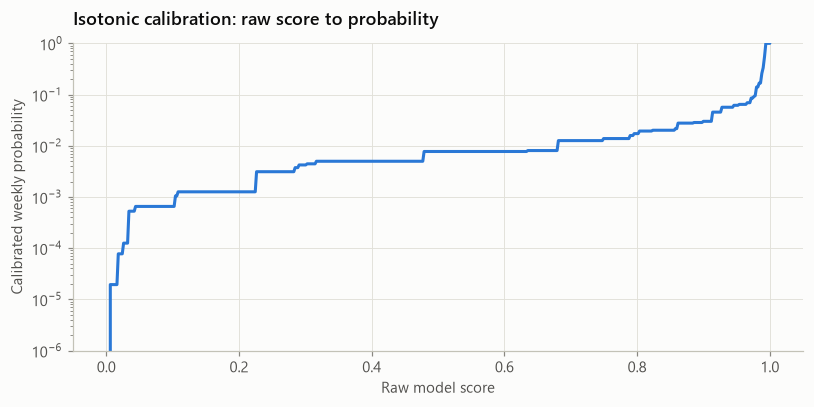

Mean raw score 10.06%, mean calibrated 0.269%, observed 0.215%
Test county-weeks calibrated to exactly 100%: 15, of which had a fire: 11


In [9]:
cal = json.loads((ARTIFACTS_DIR / "calibration.json").read_text(encoding="utf-8"))
grid = np.linspace(0, 1, 500)
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.plot(grid, model.calibrate(grid), color=viz.BLUE)
ax.set_yscale("log")
ax.set_ylim(1e-6, 1)
ax.set_title("Isotonic calibration: raw score to probability")
ax.set_xlabel("Raw model score")
ax.set_ylabel("Calibrated weekly probability")
viz.finish(ax, "both")
viz.show()
print(f"Mean raw score {raw.mean():.2%}, mean calibrated {prob.mean():.3%}, observed {y.mean():.3%}")
print(f"Test county-weeks calibrated to exactly 100%: {(prob >= 1).sum()}, of which had a fire: {y[prob >= 1].sum()}")

Note the top end: the highest raw scores map to **100%**. Isotonic regression set
that step from only 8 calibration rows (7 had fires). Those county-weeks are very
risky (most test ones did have a fire) but not certain, so the live score should cap
the probability, or treat it as a rank, rather than show 100%.

And how well those probabilities hold up on the test years. Points on the dashed line
are perfectly calibrated.

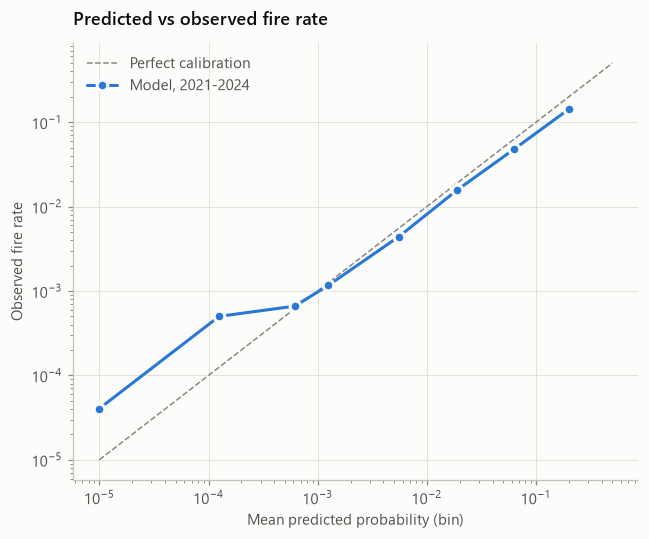

,bin,rows,fires,mean_predicted,observed_rate
0,"[0, 0.0001)","449,684",18,0.0010%,0.0040%
1,"[0.0001, 0.0003)","17,971",9,0.0125%,0.0501%
2,"[0.0003, 0.001)","71,100",47,0.0616%,0.0661%
3,"[0.001, 0.003)","39,569",46,0.1247%,0.1163%
4,"[0.003, 0.01)","55,621",245,0.5536%,0.4405%
5,"[0.01, 0.03)","24,888",392,1.9005%,1.5751%
6,"[0.03, 0.1)","9,514",455,6.2887%,4.7824%
7,"[0.1, 1)","1,621",230,19.8774%,14.1888%


In [10]:
rel = pd.DataFrame(metrics["reliability_test"])
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot([1e-5, 0.5], [1e-5, 0.5], color=viz.INK_MUTED, linestyle="--", linewidth=1, label="Perfect calibration")
ax.plot(rel["mean_predicted"], rel["observed_rate"].clip(lower=1e-5), color=viz.BLUE, marker="o",
        markersize=7, markeredgecolor=viz.SURFACE, markeredgewidth=2, label="Model, 2021-2024")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_title("Predicted vs observed fire rate")
ax.set_xlabel("Mean predicted probability (bin)")
ax.set_ylabel("Observed fire rate")
ax.legend(loc="upper left")
viz.finish(ax, "both")
viz.show()
rel.style.format({"rows": "{:,}", "fires": "{:,}", "mean_predicted": "{:.4%}", "observed_rate": "{:.4%}"})

Calibration is close between about 0.03% and 0.3%. Above that the model overestimates
by about a quarter in 2021-2024, likely because conditions shifted after the 2019-2020
calibration years; refitting just the calibrator on recent years would fix this for
the live score. Below 0.03% it underestimates, but those bins hold very few fires (27
among about 470,000 county-weeks), so the absolute error is tiny.

## Results by test year

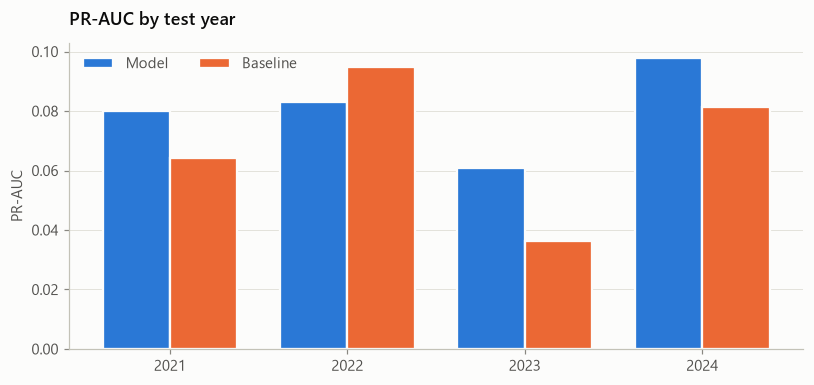

,Model,Baseline,Fires
year,,,
2021,0.080,0.064,356
2022,0.083,0.095,417
2023,0.061,0.036,287
2024,0.098,0.081,382


In [11]:
per_year = []
for year in TEST_YEARS:
    mask = (test["year"] == year).to_numpy()
    per_year.append({"year": year, "Model": average_precision_score(y[mask], prob[mask]),
                     "Baseline": average_precision_score(y[mask], baseline[mask]), "Fires": int(y[mask].sum())})
per_year = pd.DataFrame(per_year).set_index("year")

fig, ax = plt.subplots(figsize=(7.5, 3.6))
x = np.arange(len(per_year))
viz.bars(ax, x - 0.19, per_year["Model"], color=viz.BLUE, width=0.38, label="Model")
viz.bars(ax, x + 0.19, per_year["Baseline"], color=viz.ORANGE, width=0.38, label="Baseline")
ax.set_xticks(x, per_year.index)
ax.set_title("PR-AUC by test year")
ax.set_ylabel("PR-AUC")
ax.legend(loc="upper left", ncols=2)
viz.finish(ax)
viz.show()
per_year.style.format({"Model": "{:.3f}", "Baseline": "{:.3f}"})

The model beats the baseline in three of the four test years. In 2022 the baseline
was ahead (0.095 vs 0.083), so the model doesn't beat fire history alone every year.
Over the four years combined it does, clearly.

## What drives the predictions

Mean absolute SHAP value on the test years: how far each feature moves a prediction,
on average, in log-odds.

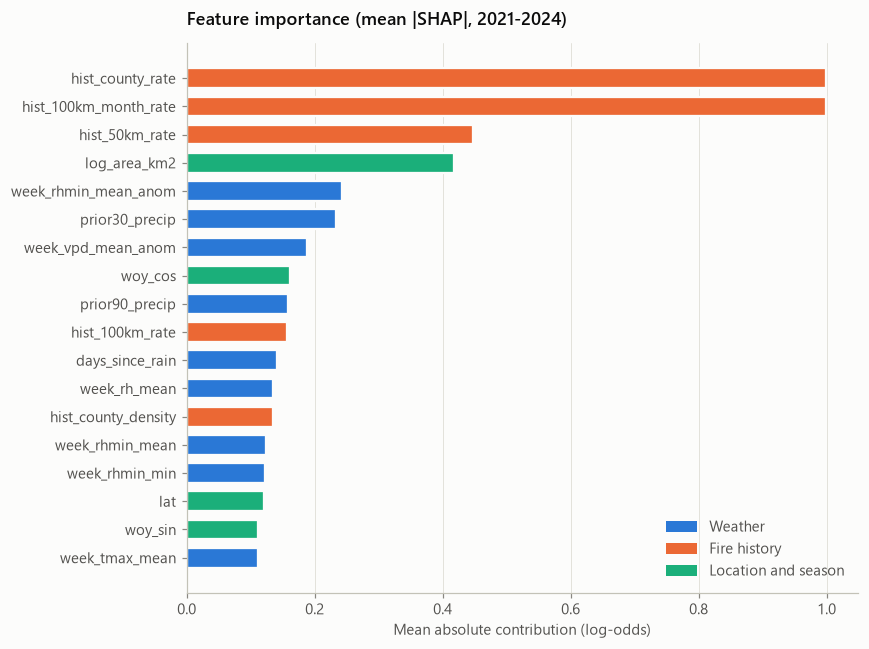

Fire history           2.736
Weather                2.569
Location and season    0.999
Name: mean_abs_shap, dtype: float64

In [12]:
importance = pd.read_csv(ARTIFACTS_DIR / "feature_importance.csv", index_col=0)
groups = {"Weather": F.WEEK_FEATURES + F.PRIOR_FEATURES + F.ANOMALY_FEATURES,
          "Fire history": F.HISTORY_FEATURES,
          "Location and season": F.STATIC_FEATURES + F.SEASON_FEATURES}
colors = {"Weather": viz.BLUE, "Fire history": viz.ORANGE, "Location and season": "#1baf7a"}
group_of = {feature: group for group, members in groups.items() for feature in members}

top = importance.head(18).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 6))
viz.hbars(ax, np.arange(len(top)), top["mean_abs_shap"], color=[colors[group_of[f]] for f in top.index])
ax.set_yticks(np.arange(len(top)), top.index)
ax.set_title("Feature importance (mean |SHAP|, 2021-2024)")
ax.set_xlabel("Mean absolute contribution (log-odds)")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in colors.values()]
ax.legend(handles, colors.keys(), loc="lower right")
viz.finish(ax, "x")
viz.show()

importance.groupby(importance.index.map(group_of))["mean_abs_shap"].sum().sort_values(ascending=False).round(3)

Fire history and county size set *where* fires are likely. The weather features set
*which weeks* are risky, and they're what a weekly score moves with.